In [33]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn import metrics

from sklearn.cluster import KMeans, MiniBatchKMeans
import matplotlib.pyplot as plt

In [69]:
#load data
# Load some categories from the training set
categories = [
    'sci.space',
    'soc.religion.christian',
    'talk.politics.guns'
]

# Uncomment the following to do the analysis on all the categories
# categories = None
dataset = fetch_20newsgroups(subset='all', categories=categories,
                             shuffle=True, random_state=42)

print("%d documents" % len(dataset.data))
print("%d categories" % len(dataset.target_names))

2894 documents
3 categories


In [71]:
labels = dataset.target
true_k = np.unique(labels).shape[0]
true_k

3

In [72]:
print(dataset.data[0])

From: Eugene.Bigelow@ebay.sun.com (Geno )
Subject: Re: Mary's assumption
Reply-To: Eugene.Bigelow@ebay.sun.com
Organization: Sun Microsystems, Inc.
Lines: 9

>When Elizabeth greeted Mary, Elizabeth said something to the effect that
>Mary, out of all women, was blessed.  If so, it appears that this
>exactly places Mary beyond the sanctification of normal humanity.

I remember a couple of times when my ex-girlfriend said that she thought she
was blessed because of her son (whom she loved dearly). In fact, I've heard
people refer to someone as being blessed quite a few times. It's a common
figure of speech. Considering that Elizabeth was just another human, I think
this passage offers nothing towards justifying the "blessedness" of Mary. 



In [73]:
vectorizer = TfidfVectorizer(max_df=0.5, max_features=1000,
                                 min_df=2, stop_words='english',
                                 use_idf=True)
X = vectorizer.fit_transform(dataset.data)
print(X.shape)
print(X[0:2,:]) # print row 0 & 1

(2894, 1000)
  (0, 864)	0.3630487691665399
  (0, 209)	0.11779511345034528
  (0, 562)	0.6891168795967529
  (0, 743)	0.09134103137978301
  (0, 771)	0.1806748443653505
  (0, 310)	0.1356437925645759
  (0, 978)	0.14202680249352292
  (0, 88)	0.14876354060008076
  (0, 321)	0.11873900245119379
  (0, 667)	0.14539903234279564
  (0, 742)	0.11009207046334236
  (0, 242)	0.13191179895412508
  (0, 903)	0.22839738093554562
  (0, 900)	0.11107136883850752
  (0, 824)	0.14076966143079042
  (0, 332)	0.10248731750817608
  (0, 946)	0.09515641895446962
  (0, 422)	0.10973226898043123
  (0, 657)	0.06579607942702867
  (0, 716)	0.10765287702429117
  (0, 217)	0.1279320947156025
  (0, 347)	0.14139218764214412
  (0, 491)	0.06398164656628513
  (0, 443)	0.1122093357964344
  (0, 897)	0.06865389123727407
  :	:
  (1, 681)	0.0690250805400478
  (1, 301)	0.06269354324915558
  (1, 139)	0.10732358457912551
  (1, 272)	0.12472312734211581
  (1, 792)	0.1172206101968218
  (1, 979)	0.057993606913467326
  (1, 698)	0.095234964035235

In [74]:
X_d = X.todense()
print(X_d[0])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.14876354 0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.   

In [75]:
svd = TruncatedSVD(2) # reduce to 2 dimensions 
normalizer = Normalizer(copy=False)
lsa = make_pipeline(svd, normalizer)
X_2D = lsa.fit_transform(X)
print(X_2D.shape)

(2894, 2)


In [77]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_d)
print(X_2D.shape)

(2894, 2)


No handles with labels found to put in legend.


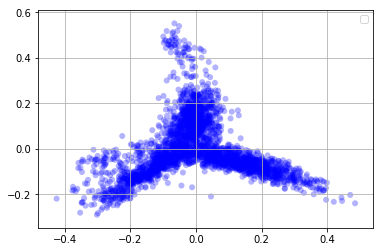

In [78]:
fig, ax = plt.subplots()
ax.scatter(x=X_2D[:,0], y=X_2D[:,1], c='blue',
               alpha=0.3, edgecolors='none')
ax.legend()
ax.grid(True)
plt.show()

In [79]:
km = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1,
                verbose=True)
km.fit(X)
labels = km.labels_
print(labels)

Initialization complete
Iteration  0, inertia 5148.111
Iteration  1, inertia 2686.563
Iteration  2, inertia 2672.417
Iteration  3, inertia 2671.079
Iteration  4, inertia 2671.009
Iteration  5, inertia 2670.993
Iteration  6, inertia 2670.991
Converged at iteration 6: center shift 0.000000e+00 within tolerance 9.511131e-08
[1 0 2 ... 1 1 0]


No handles with labels found to put in legend.


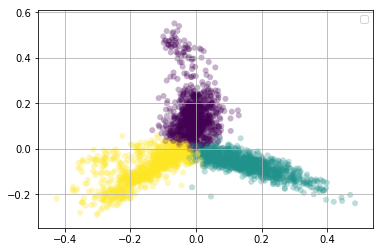

In [80]:

fig, ax = plt.subplots()
ax.scatter(x=X_2D[:,0], y=X_2D[:,1], c=labels,
               alpha=0.3, edgecolors='none')
ax.legend()
ax.grid(True)

plt.show()

In [81]:
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
X_3D = pca.fit_transform(X_d)
print(X_3D.shape)

(2894, 3)


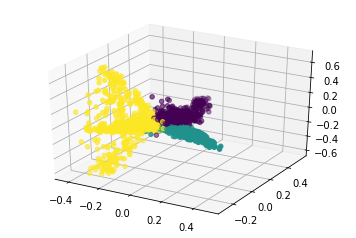

In [83]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter3D(X_3D[:,0], X_3D[:,1], X_3D[:,2], c=labels);
plt.show()
